
# 📈 ARIMA Time-Series Forecasting – AAPL Stock Case Study

This notebook builds and evaluates an ARIMA model to forecast Apple Inc. (AAPL) stock returns using historical weekly closing prices. It includes:
- Data preprocessing
- Visual exploration
- ARIMA model training
- Forecasting future prices
- Evaluation of forecast accuracy

---


## Step 1: Data Import & Preparation

We begin by importing the CSV data, parsing dates, and converting the daily closing prices to weekly closing prices (the last trading day of each week) to prepare for time-series analysis.


In [2]:
%matplotlib inline

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import datetime
%config InlineBackend.figure_format = 'retina'

df = pd.read_csv('AAPL10Y.csv')

df['date'] = pd.to_datetime(df['date'])
df.sort_values('date', inplace=True)
df.set_index('date', inplace=True)
df_week = df.resample('W').last()
df_week = df_week[['close']]
df_week['weekly_ret'] = np.log(df_week['close']).diff()

# drop null rows
df_week.dropna(inplace=True)


## Step 2: Visualizing Weekly AAPL Log Returns

To better understand the trend and behavior of the stock, we plot the weekly log returns. This helps us visually assess stationarity and volatility patterns.


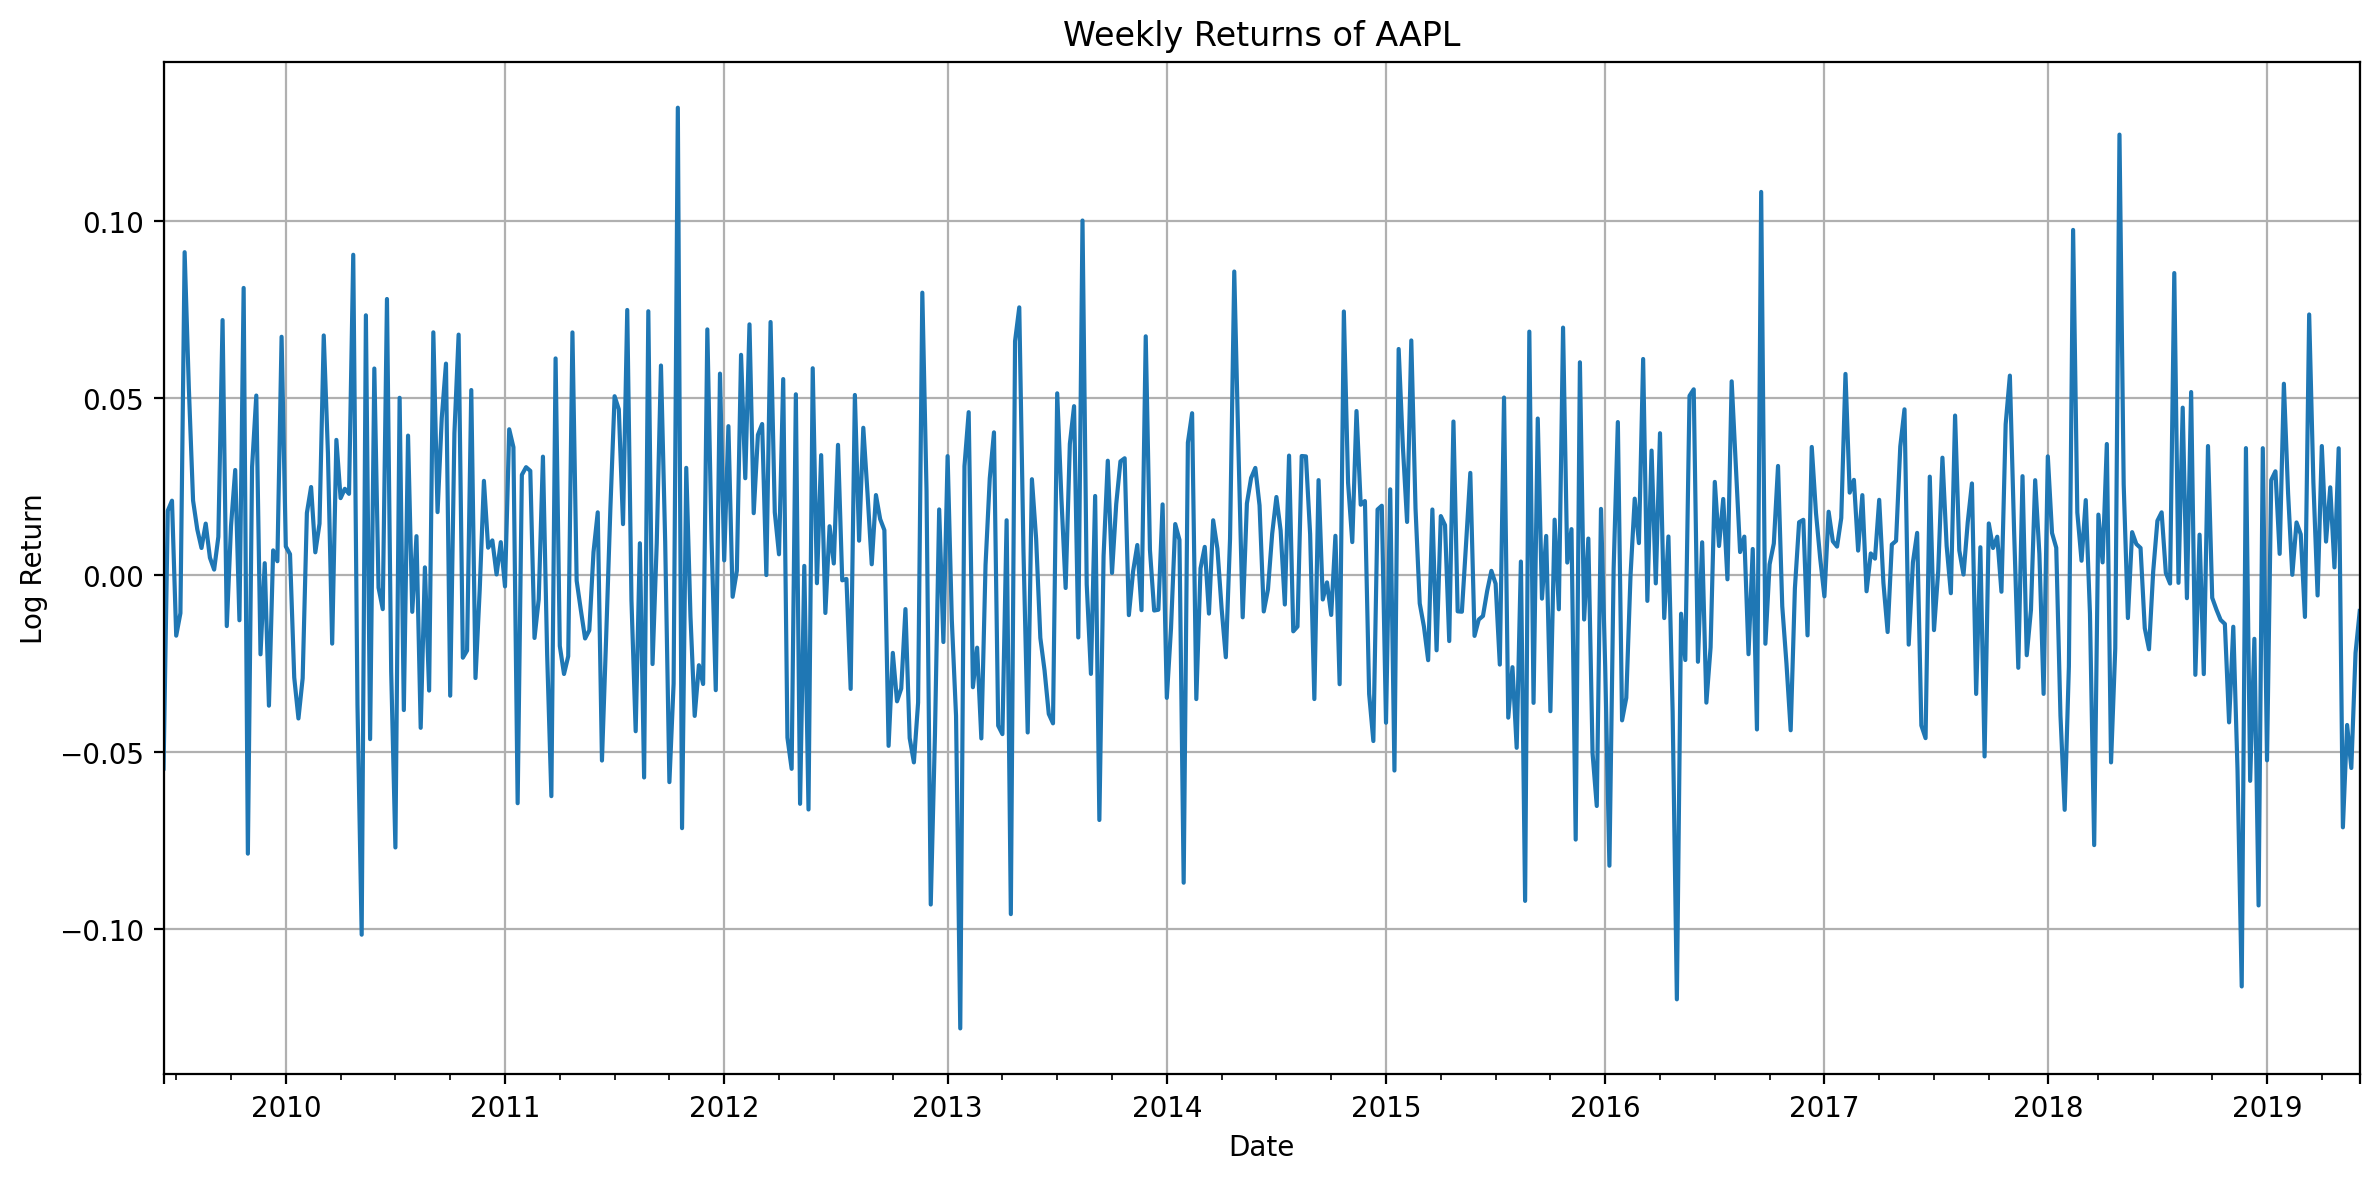

In [3]:


import matplotlib.pyplot as plt

df_week['weekly_ret'].plot(kind='line', figsize=(12, 6))
plt.title("Weekly Returns of AAPL")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.grid(True)
plt.tight_layout()
plt.show()

## Step 3: Visual Check for Stationarity – Rolling Mean & Standard Deviation

To apply ARIMA effectively, the time series must be **stationary** — meaning its statistical properties (mean, variance) do not change over time.

We plot:
- The original log returns
- A 20-week rolling mean
- A 20-week rolling standard deviation

📌 If the rolling mean and std stay relatively flat → the series may be stationary.  
If they shift over time → we need differencing or transformation.


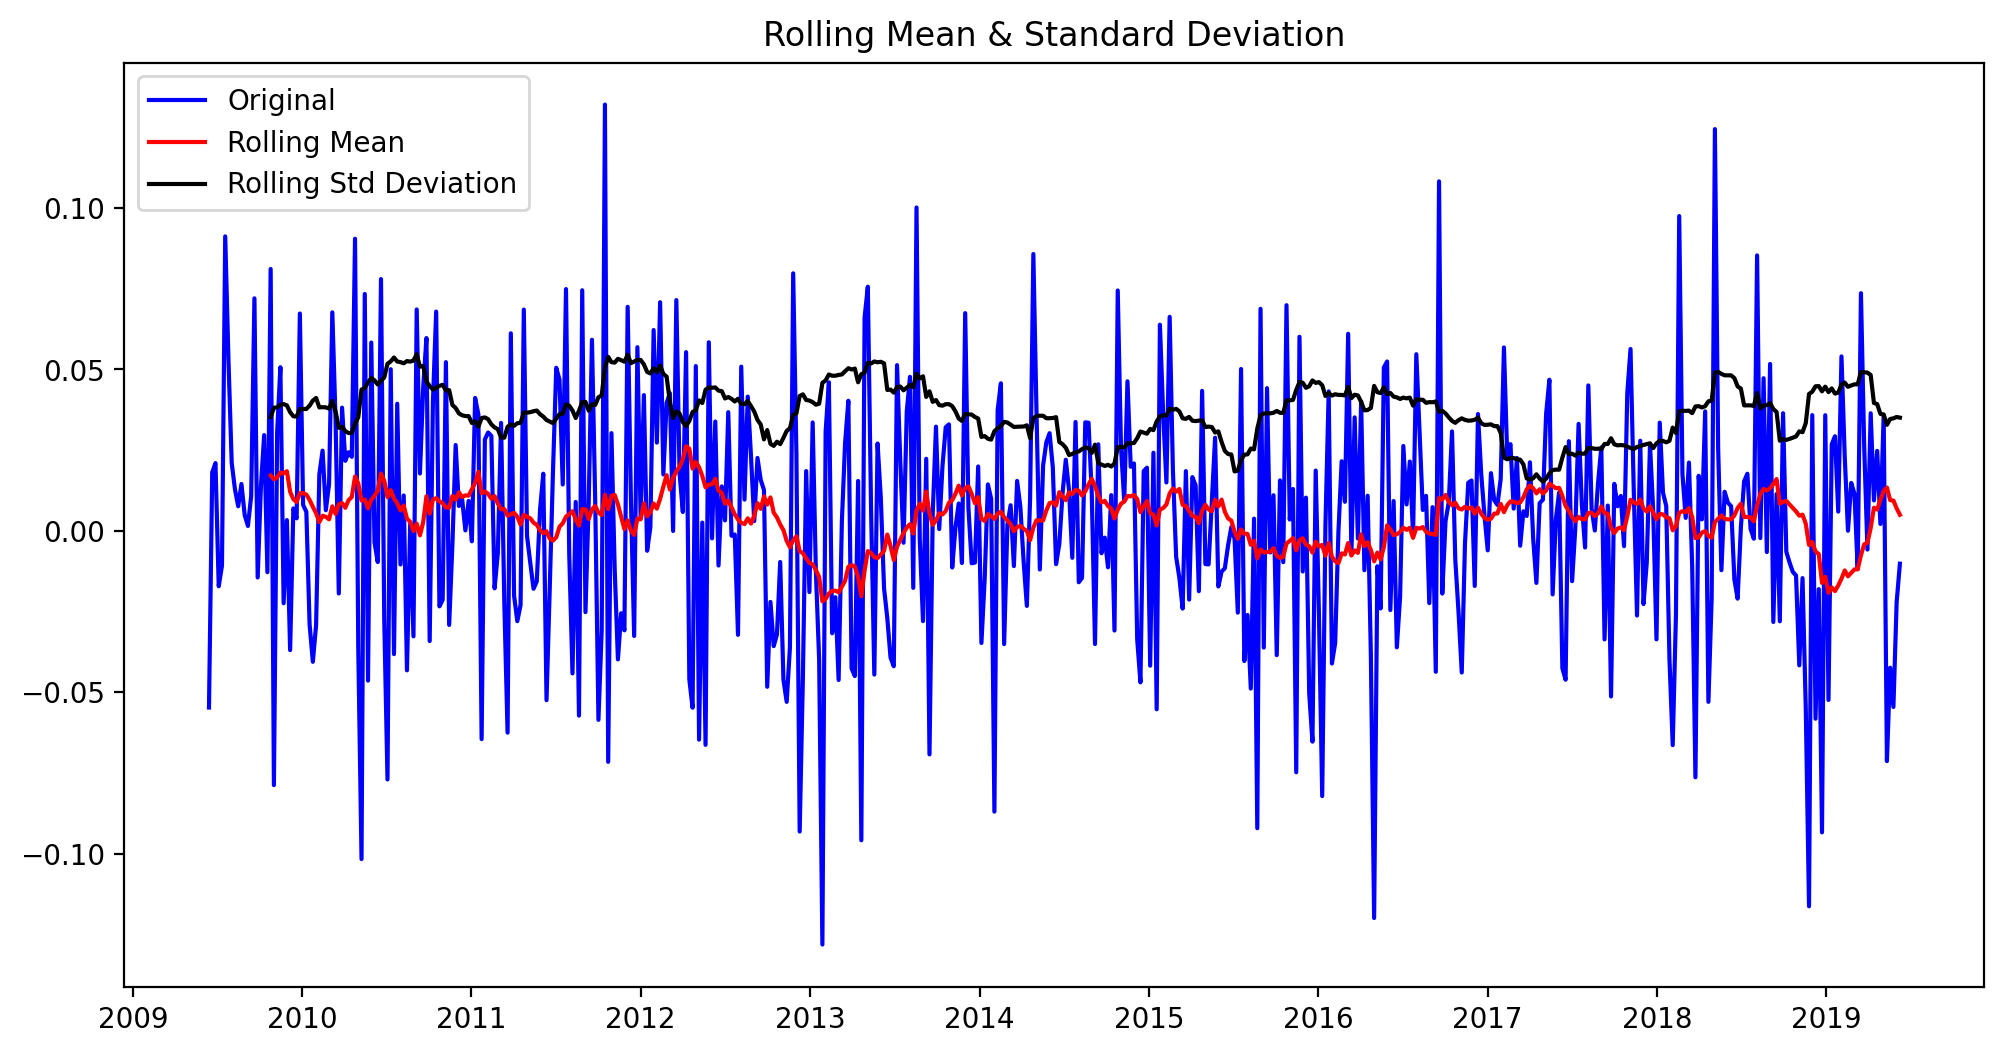

In [4]:
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
udiff = df_week.drop(['close'], axis=1)
rolmean = udiff.rolling(20).mean()
rolstd = udiff.rolling(20).std()

plt.figure(figsize=(12, 6))
orig = plt.plot(udiff, color='blue', label='Original')
mean = plt.plot(rolmean, color='red', label='Rolling Mean')
std = plt.plot(rolstd, color='black', label = 'Rolling Std Deviation')
plt.title('Rolling Mean & Standard Deviation')
plt.legend(loc='best')
plt.show(block=False)

## Step 4: Dickey-Fuller Test for Stationarity

The Augmented Dickey-Fuller (ADF) test is a statistical test used to confirm whether a time series is stationary.

- **Null Hypothesis (H₀):** The series has a unit root (non-stationary)
- **Alternative Hypothesis (H₁):** The series is stationary

We examine:
- The **Test Statistic**: should be lower than the critical value
- The **p-value**: should be below 0.05 to reject the null

📌 If p < 0.05 → we conclude the series is stationary and suitable for ARIMA.


In [5]:
# Perform Dickey-Fuller test
dftest = sm.tsa.adfuller(udiff.weekly_ret, autolag='AIC')
dfoutput = pd.Series(dftest[0:4], index=['Test Statistic', 'p-value', '#Lags Used', 'Number of Observations Used'])
for key, value in dftest[4].items():
    dfoutput['Critical Value ({0})'.format(key)] = value
    
dfoutput

Test Statistic                 -24.716820
p-value                          0.000000
#Lags Used                       0.000000
Number of Observations Used    521.000000
Critical Value (1%)             -3.442964
Critical Value (5%)             -2.867103
Critical Value (10%)            -2.569733
dtype: float64

## Step 5: ACF and PACF Plots for Model Parameter Selection

To identify the appropriate ARIMA model parameters:
- **ACF (Autocorrelation Function)** helps suggest the **MA (q)** term
- **PACF (Partial Autocorrelation Function)** helps suggest the **AR (p)** term

We plot both:
- ACF shows correlation with lagged values (q)
- PACF shows direct correlation at each lag (p), excluding intermediates

📌 Use these plots to visually estimate the initial values for `p` and `q` before training the ARIMA model.


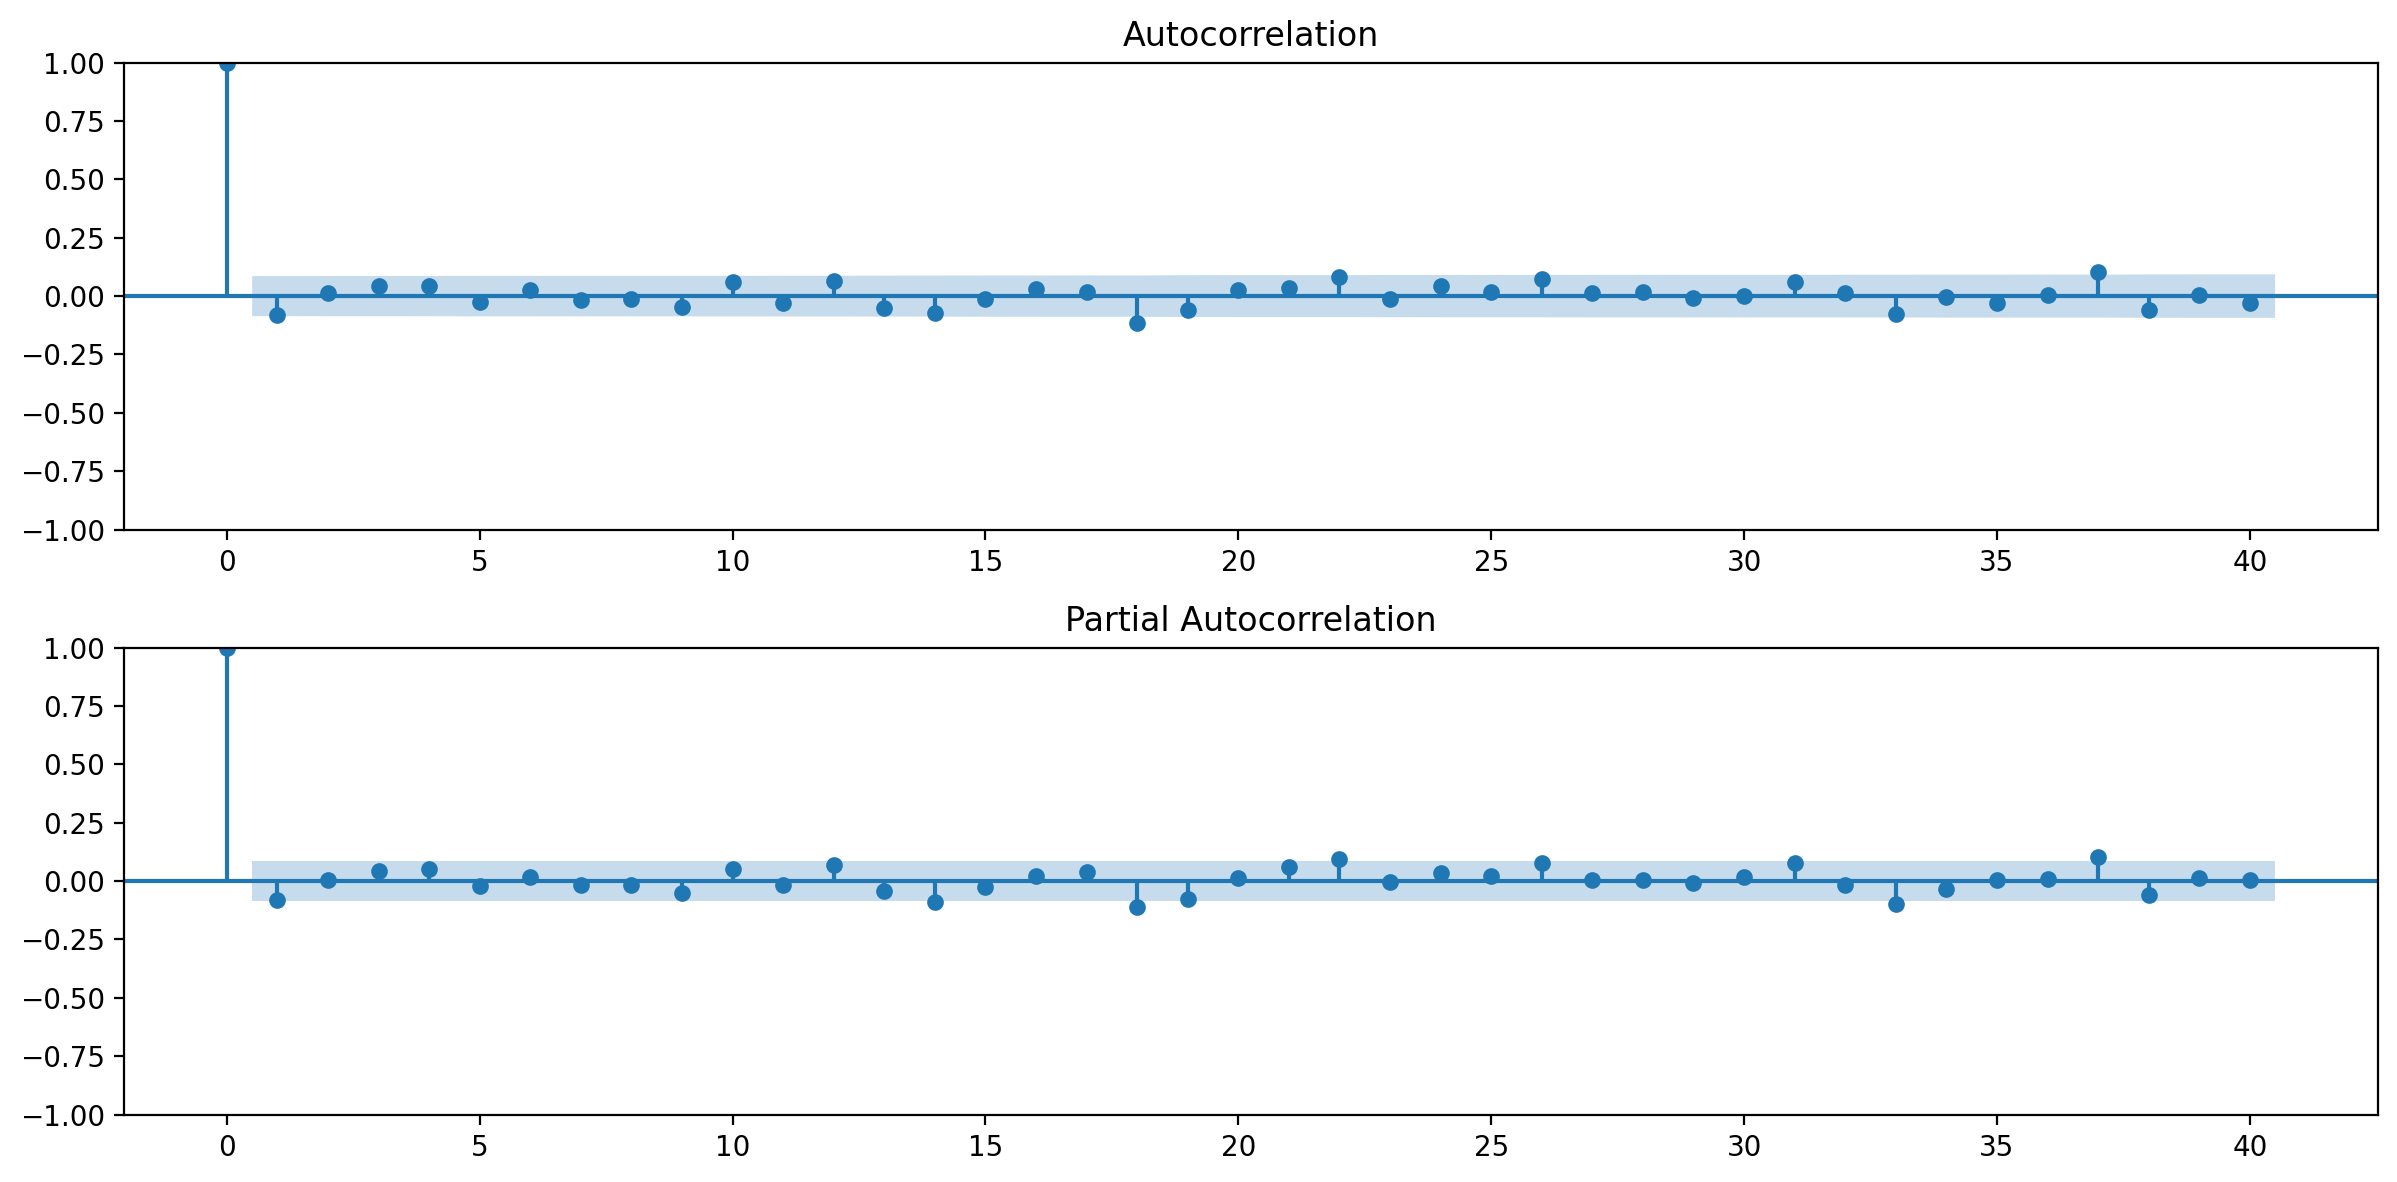

In [6]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.figure(figsize=(12,6))
plt.subplot(211)
plot_acf(df_week['weekly_ret'], ax=plt.gca(), lags=40)
plt.subplot(212)
plot_pacf(df_week['weekly_ret'], ax=plt.gca(), lags=40)
plt.tight_layout()
plt.show()

**Note:** The ACF and PACF plots give only a rough starting point. The final `(p, q)` is chosen objectively with AIC/BIC in Step 5b below.

## Step 5b: Order Selection by AIC / BIC (training data only)

Reading orders off ACF/PACF plots is subjective, so we fit every `ARIMA(p, 0, q)` with `p, q` from 0 to 4 and compare them with information criteria (lower is better).

- **AIC** rewards fit; **BIC** penalises extra parameters more strongly. We select by BIC because weekly returns carry only a weak signal.
- The search uses **only the first 80% of the weeks (the training period)**. The last 20% is never seen during order selection, so the backtests in Step 9 stay a genuine out-of-sample test.
- If `ARIMA(0,0,0)` (just a constant mean) is selected, that itself is a finding: the returns have almost no linear structure.

In [7]:
import warnings
from statsmodels.tsa.arima.model import ARIMA

# Chronological 80/20 split, defined here so order selection never sees the test period
split = int(len(df_week) * 0.8)
train_ret = df_week['weekly_ret'].iloc[:split]

rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for p in range(0, 5):
        for q in range(0, 5):
            try:
                res = ARIMA(train_ret, order=(p, 0, q)).fit()
                rows.append({'p': p, 'q': q, 'AIC': res.aic, 'BIC': res.bic})
            except Exception:
                pass

order_grid = pd.DataFrame(rows)
print(f"Order selection uses the first {split} weeks only (training period).")
print(order_grid.sort_values('BIC').head(5).round(2).to_string(index=False))

p_order, q_order = order_grid.sort_values('BIC').iloc[0][['p', 'q']].astype(int)
print(f"\nSelected order by BIC: ARIMA({p_order},0,{q_order})")

Order selection uses the first 417 weeks only (training period).
 p  q      AIC      BIC
 0  0 -1545.31 -1537.25
 0  1 -1548.30 -1536.20
 1  0 -1548.15 -1536.05
 2  0 -1546.42 -1530.29
 0  2 -1546.31 -1530.18

Selected order by BIC: ARIMA(0,0,0)


## Step 6: Train ARIMA Model

We now train the ARIMA model using the order selected in Step 5b.

- `p`, `q`: chosen by BIC in Step 5b (on the training period only)
- `d = 0`: Differencing (already done in preprocessing)

The `ARIMA(p,0,q)` model is fitted to the **training portion** of the weekly log returns (the first 80%). The last 20% is kept aside for testing.  
The `.summary()` output gives the coefficients, standard errors, and diagnostics to assess model quality.

📌 Check the p-values of the individual coefficients: terms with very large p-values add little to the model.

In [8]:
from statsmodels.tsa.arima.model import ARIMA

ar1 = ARIMA(train_ret, order = (p_order, 0, q_order)).fit()
ar1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:             weekly_ret   No. Observations:                  417
Model:                          ARIMA   Log Likelihood                 774.657
Date:                Sat, 24 Oct 2026   AIC                          -1545.314
Time:                        14:21:40   BIC                          -1537.248
Sample:                    06-14-2009   HQIC                         -1542.125
                         - 06-04-2017                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0048      0.002      2.604      0.009       0.001       0.008
sigma2         0.0014   8.77e-05     16.267      0.000       0.001       0.002
===================================================================================
Ljung-Box (L1) (Q):                   4.82   Jarque-Bera (JB):                 6.70
Prob(Q):                              0.03   Prob(JB):                         0.04
Heteroskedasticity (H):               0.71   Skew:                            -0.14
Prob(H) (two-sided):                  0.05   Kurtosis:                         3.56
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [9]:
model = ARIMA(train_ret, order=(p_order, 0, q_order))
arima_result = model.fit()
print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:             weekly_ret   No. Observations:                  417
Model:                          ARIMA   Log Likelihood                 774.657
Date:                Sat, 24 Oct 2026   AIC                          -1545.314
Time:                        14:21:41   BIC                          -1537.248
Sample:                    06-14-2009   HQIC                         -1542.125
                         - 06-04-2017                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0048      0.002      2.604      0.009       0.001       0.008
sigma2         0.0014   8.77e-05     16.267      0.000       0.001       0.002
Ljung-Box (L1) (Q):                   4.82   Jarque-

## Step 7: Visual Comparison – Actual vs Fitted Values

To visually assess how well the ARIMA(p,0,q) model fits the data, we plot:

- The actual weekly log returns of the **training period** (in **blue**)
- The model’s fitted values (in **red**)

A good fit should have the red line closely tracking the blue line without lag or large gaps.

📌 This plot helps us qualitatively evaluate the model's in-sample performance.

### NOTE: Our model doesn't do a good job predicting variance in the original data (peaks and valleys).


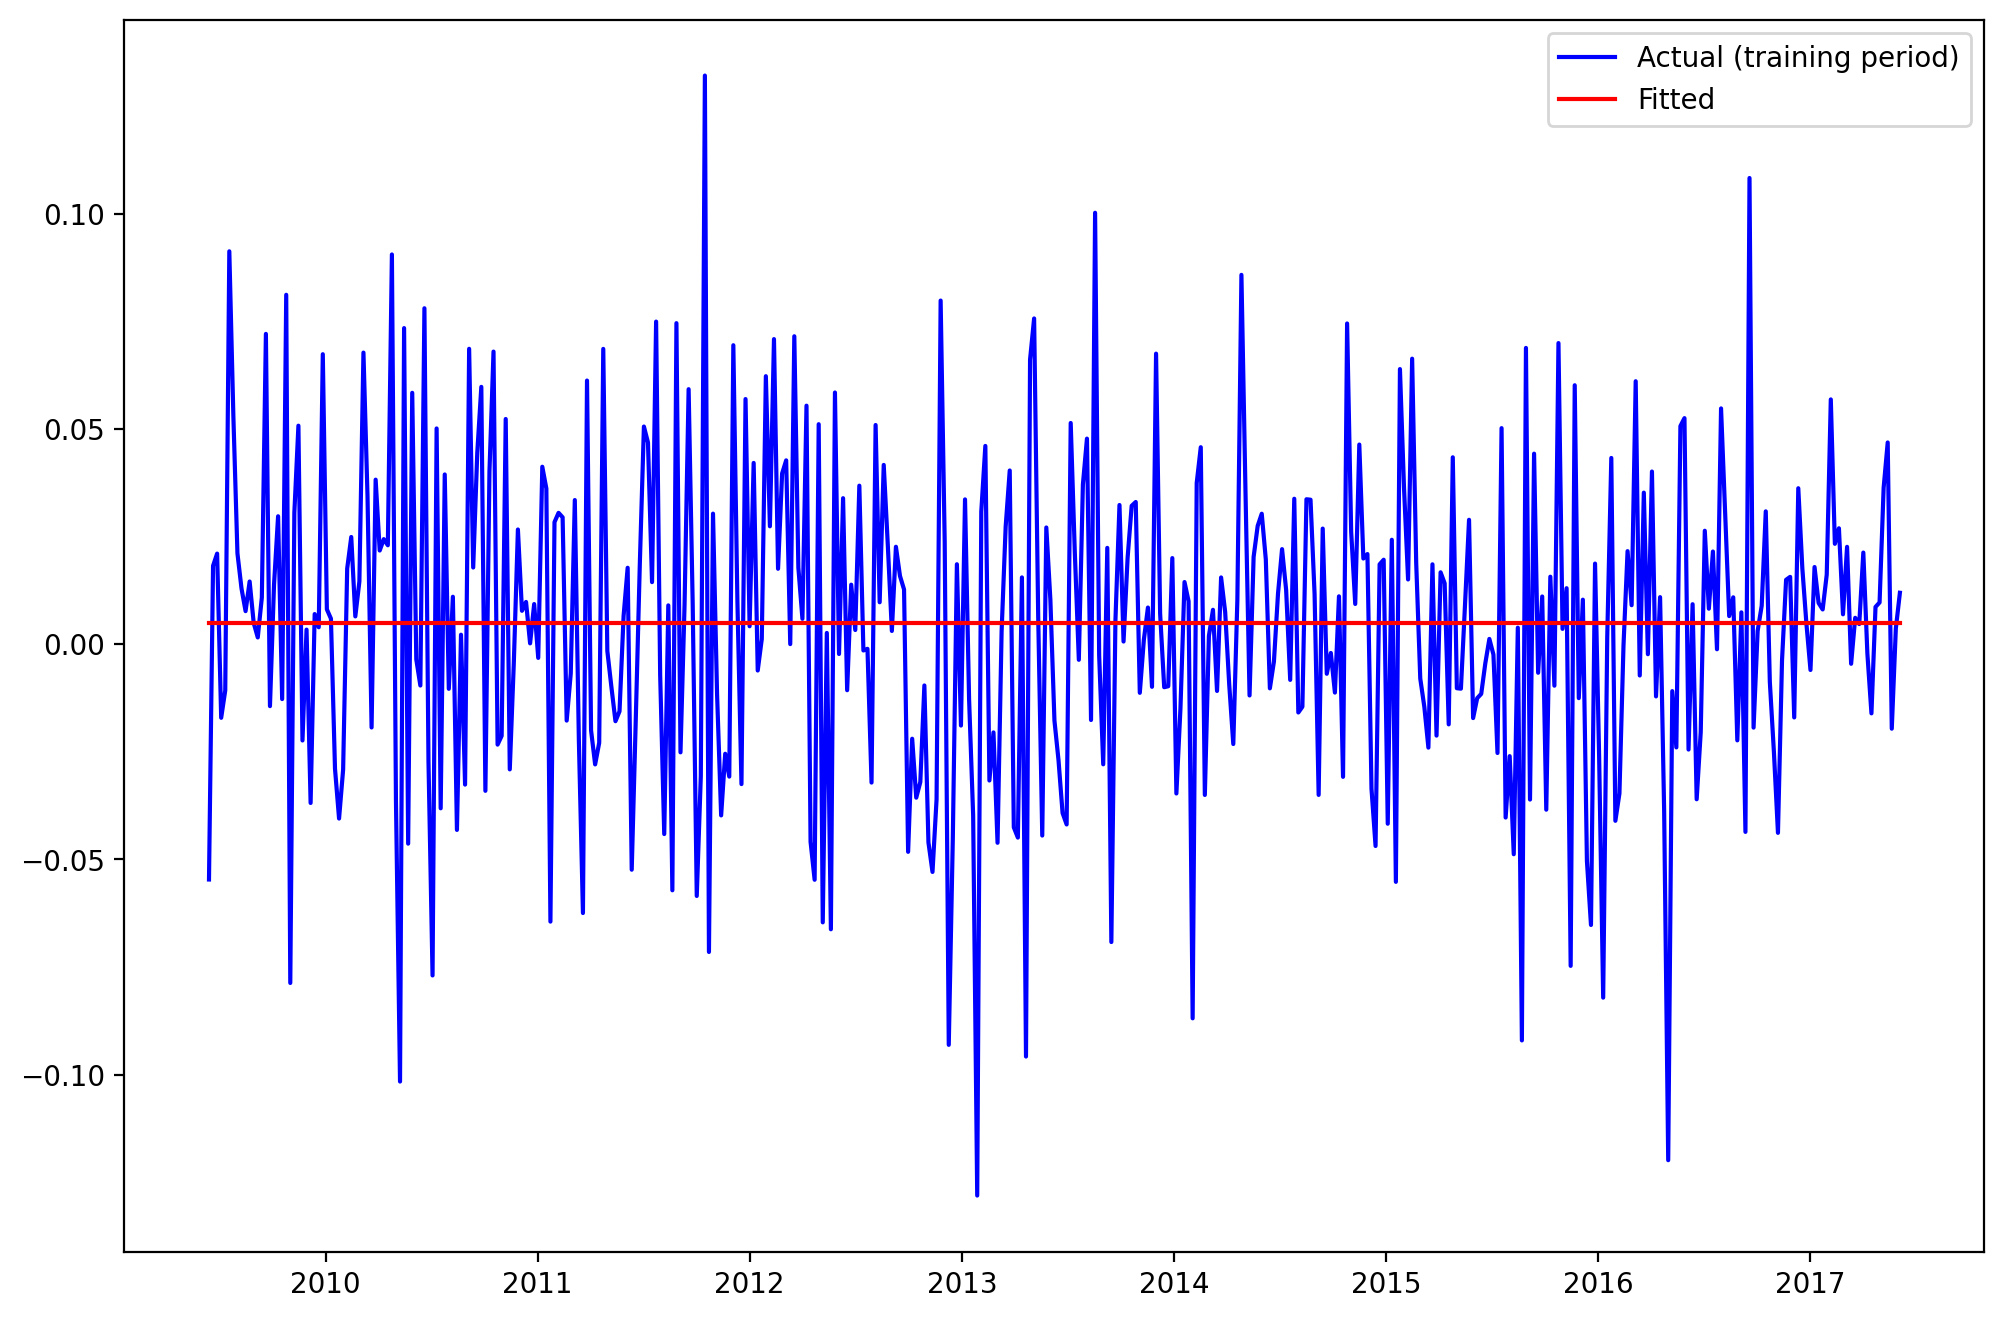

In [10]:
plt.figure(figsize=(12, 8))
plt.plot(train_ret.index, train_ret.values, color='blue', label='Actual (training period)')
preds = ar1.fittedvalues
plt.plot(train_ret.index, preds, color='red', label='Fitted')
plt.legend()
plt.show()

## Step 8: Forecasting AAPL Prices from the End of the Training Period

Using the ARIMA(p,0,q) model trained on the training period only, we forecast the next `10` weeks, which are the **first 10 weeks of the test period**:

- The model predicts **log returns**, which are exponentiated and applied to the last *training* price to generate price levels.
- We plot the forecasted prices (in green) against the actual prices (in blue), so the forecast can be checked against what really happened.

📌 Because these weeks were never used for fitting or order selection, this is an honest check of the forecast.


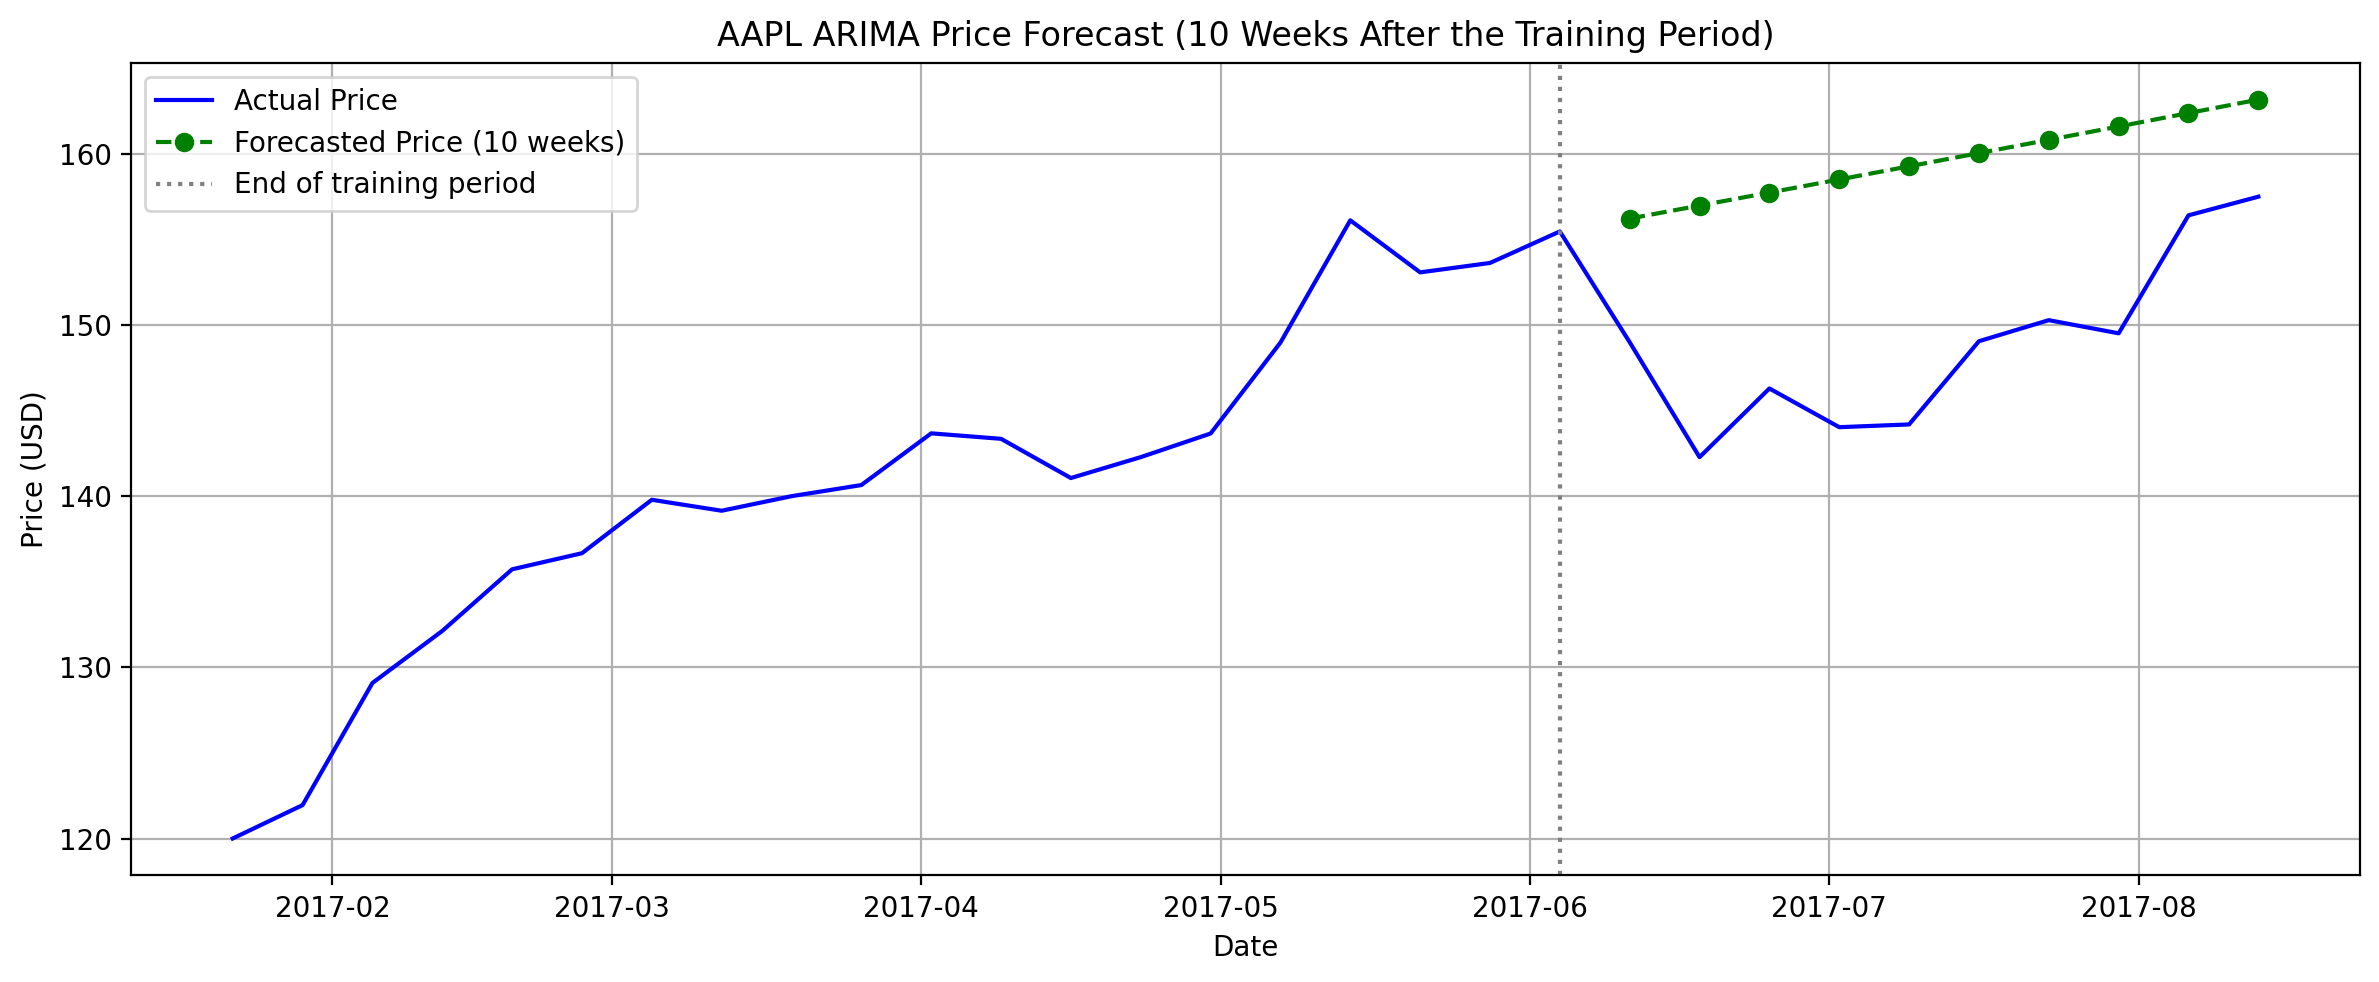

Forecasted prices: [156.2, 156.96, 157.72, 158.48, 159.25, 160.02, 160.8, 161.58, 162.36, 163.15]
Actual prices:     [148.98, 142.27, 146.28, 144.02, 144.18, 149.04, 150.27, 149.5, 156.39, 157.48]
Forecasted dates: DatetimeIndex(['2017-06-11', '2017-06-18', '2017-06-25', '2017-07-02',
               '2017-07-09', '2017-07-16', '2017-07-23', '2017-07-30',
               '2017-08-06', '2017-08-13'],
              dtype='datetime64[ns]', name='date', freq='W-SUN')


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA


steps = 10  # Number of weeks to forecast, starting right after the training period

# Model trained on the training period only
arima_result = ARIMA(train_ret, order=(p_order, 0, q_order)).fit()

# Forecasted log returns for the first `steps` test weeks
forecasted_log_returns = arima_result.forecast(steps=steps).values

# Start from the last TRAINING price
last_price = df_week['close'].iloc[split - 1]

# Transform log returns to price forecasts
forecasted_prices = []
current_price = last_price
for log_ret in forecasted_log_returns:
    current_price *= np.exp(log_ret)
    forecasted_prices.append(current_price)

# The forecast dates are the actual dates of the first test weeks
forecast_dates = df_week.index[split:split + steps]
actual_prices = df_week['close'].iloc[split:split + steps]

# Plot actual and forecasted prices
plt.figure(figsize=(12, 5))
plt.plot(df_week['close'].iloc[split - 20:split + steps], label='Actual Price', color='blue')
plt.plot(forecast_dates, forecasted_prices, label=f'Forecasted Price ({steps} weeks)', color='green', marker='o', linestyle='--')
plt.axvline(df_week.index[split - 1], color='gray', linestyle=':', label='End of training period')
plt.title(f"AAPL ARIMA Price Forecast ({steps} Weeks After the Training Period)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Forecasted prices:", [round(float(p), 2) for p in forecasted_prices])
print("Actual prices:    ", [round(float(p), 2) for p in actual_prices])
print("Forecasted dates:", forecast_dates)

**Further tuning of the ARIMA model may improve forecast accuracy.**

## Step 9: Backtesting the ARIMA Model

To assess the out-of-sample performance of the ARIMA(p,0,q) model, we apply a backtesting approach:

- **80% of the data** is used for training, and **20% for testing**
- The model is fit on the training set and used to forecast the test set
- We compare predicted vs actual log returns visually and with metrics:

📊 Metrics used:
- **MSE** (Mean Squared Error)
- **MAE** (Mean Absolute Error)

MAPE is not used: returns are close to zero, so percentage errors are huge and meaningless.

The fitted model is compared with a **baseline that always predicts the training-period mean**. A multi-step forecast from an ARMA model quickly flattens to the mean, so a **rolling one-step-ahead backtest** follows in the next cells for a fairer test.


The ARIMA order was selected on the training period only (Step 5b), so the test period is untouched by model selection.

Backtest MSE: 0.001411, MAE: 0.0277
Baseline (train mean) MSE: 0.001411, MAE: 0.0277


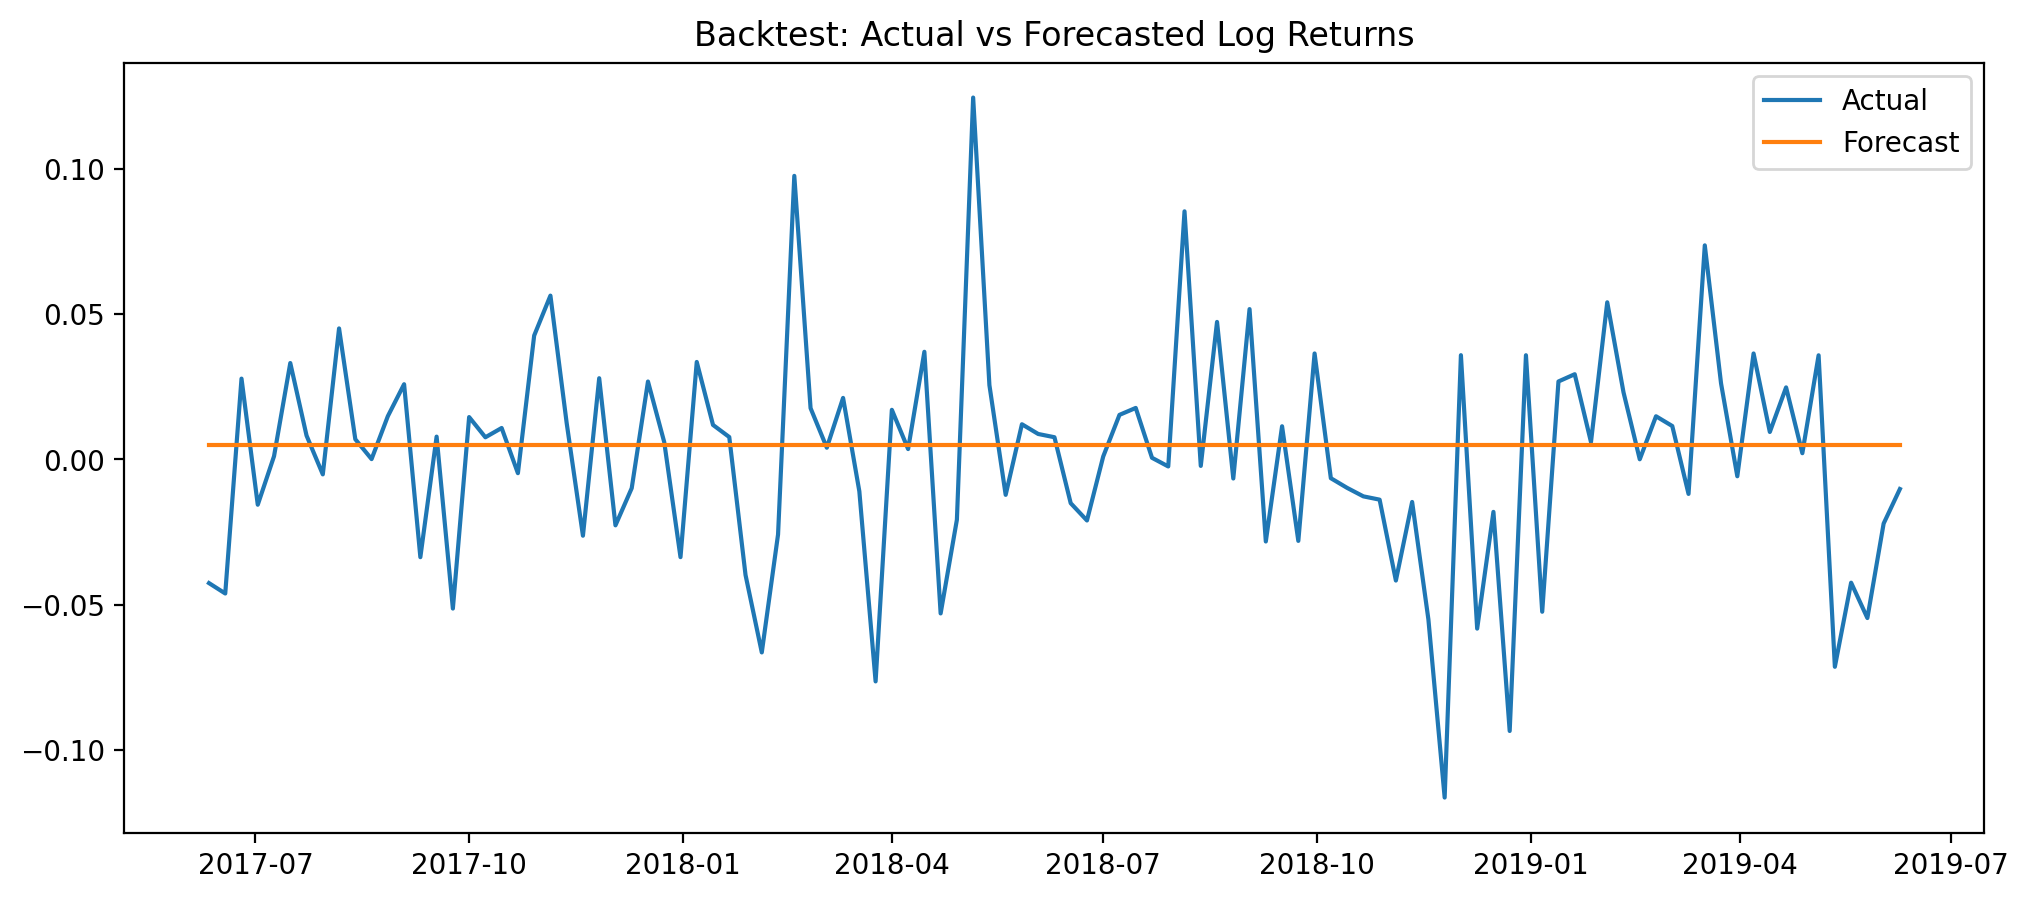

In [12]:
# 'split' (80/20 chronological split) is defined in Step 5b
train = df_week['weekly_ret'][:split]
test = df_week['weekly_ret'][split:]

model_bt = ARIMA(train, order=(p_order, 0, q_order))
result_bt = model_bt.fit()
forecast_bt = result_bt.forecast(steps=len(test))

# Error metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error
mse = mean_squared_error(test, forecast_bt)
mae = mean_absolute_error(test, forecast_bt)
print(f"Backtest MSE: {mse:.6f}, MAE: {mae:.4f}")

# Baseline: always predict the training mean
baseline = np.full(len(test), train.mean())
mse_base = mean_squared_error(test, baseline)
mae_base = mean_absolute_error(test, baseline)
print(f"Baseline (train mean) MSE: {mse_base:.6f}, MAE: {mae_base:.4f}")

plt.figure(figsize=(12,5))
plt.plot(test.index, test.values, label='Actual')
plt.plot(test.index, forecast_bt, label='Forecast')
plt.legend()
plt.title("Backtest: Actual vs Forecasted Log Returns")
plt.show()

### Rolling one-step-ahead backtest

For each test week, the model parameters are refit on all data up to the previous week and used to forecast only the next week. The order `(p, q)` stays fixed at the value chosen on the training period. We compare with two naive baselines (zero return and expanding historical mean) using MSE, MAE, directional accuracy, out-of-sample R² versus the historical mean (positive means the model beats the mean), and a Diebold-Mariano test of whether any difference in squared error is statistically significant.

We also check the **95% prediction interval**: if the interval assumptions are reasonable, about 95% of actual test returns should fall inside it.

In [13]:
import scipy.stats as st

rolling_preds, rolling_se = [], []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for t in range(split, len(df_week)):
        fit_t = ARIMA(df_week['weekly_ret'].iloc[:t], order=(p_order, 0, q_order)).fit()
        fc = fit_t.get_forecast(1)
        rolling_preds.append(float(fc.predicted_mean.iloc[0]))
        rolling_se.append(float(fc.se_mean.iloc[0]))

rolling_preds = np.array(rolling_preds)
rolling_se = np.array(rolling_se)
hist_mean = np.array([df_week['weekly_ret'].iloc[:t].mean() for t in range(split, len(df_week))])
zero_pred = np.zeros(len(test))
actual = test.values

def score(y, yhat):
    return {'MSE': np.mean((y - yhat)**2), 'MAE': np.mean(np.abs(y - yhat)),
            'Directional acc.': np.mean(np.sign(y) == np.sign(yhat)) if np.any(yhat != 0) else np.nan}

results = pd.DataFrame({'ARIMA (rolling)': score(actual, rolling_preds),
                        'Historical mean': score(actual, hist_mean),
                        'Zero return': score(actual, zero_pred)}).T
print(results.round(5))

oos_r2 = 1 - np.sum((actual - rolling_preds)**2) / np.sum((actual - hist_mean)**2)
print(f"\nOut-of-sample R^2 vs historical mean: {oos_r2:.4f}")

# Diebold-Mariano test (squared error, 1-step): d > 0 favours ARIMA
d = (actual - hist_mean)**2 - (actual - rolling_preds)**2
if np.std(d, ddof=1) > 0:
    dm_stat = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))
    dm_p = 2 * (1 - st.norm.cdf(abs(dm_stat)))
    print(f"Diebold-Mariano: stat={dm_stat:.2f}, p-value={dm_p:.3f}")
else:
    dm_p = np.nan
    print("Diebold-Mariano: ARIMA and the historical mean give identical forecasts, so there is nothing to test.")

# Coverage of the 95% one-step prediction interval
coverage = np.mean(np.abs(actual - rolling_preds) <= 1.96 * rolling_se)
print(f"95% interval coverage on test weeks: {coverage:.1%} (target: about 95%)")

                     MSE      MAE  Directional acc.
ARIMA (rolling)  0.00141  0.02772           0.57143
Historical mean  0.00141  0.02772           0.57143
Zero return      0.00140  0.02789               NaN

Out-of-sample R^2 vs historical mean: 0.0000
Diebold-Mariano: stat=0.96, p-value=0.336
95% interval coverage on test weeks: 93.3% (target: about 95%)


**How to read these results**

- Passing the stationarity test or fitting without errors says nothing about predictive power. Weekly stock returns can be perfectly stationary and still be almost unpredictable.
- The model is only useful if it **beats the baselines out-of-sample**: lower MSE/MAE than the historical mean, a positive out-of-sample R², and ideally a significant Diebold-Mariano result.
- Directional accuracy near 50% means the model is no better than a coin flip at calling up/down weeks.
- Coverage far below 95% means the model's intervals are too narrow (overconfident).

## Step 10: Forecast Prediction Interval

In addition to forecasting future AAPL prices, we compute a **model-based prediction interval** to represent the range of uncertainty in our model's predictions.

- `conf_int()` only gives bounds for each *individual* week's return, so chaining those bounds into a price band would assume the worst (or best) case happens every single week and overstate the uncertainty
- Instead, we **simulate 5,000 future return paths** from the fitted model, convert each into a price path, and take the 2.5th and 97.5th percentiles at each week
- This gives a shaded 95% band whose width grows realistically with the forecast horizon

The forecast starts at the **end of the training period**, and the actual prices of those weeks are plotted on top, so you can see whether reality stayed inside the band.

⚠️ The band is only as good as the model's assumptions (constant variance, normally distributed errors). It is **not a guarantee** about future prices. The residual tests in Step 11 and the coverage check in Step 9 show whether those assumptions are reasonable here.

📌 A prediction interval makes the forecast more informative and transparent about its uncertainty.


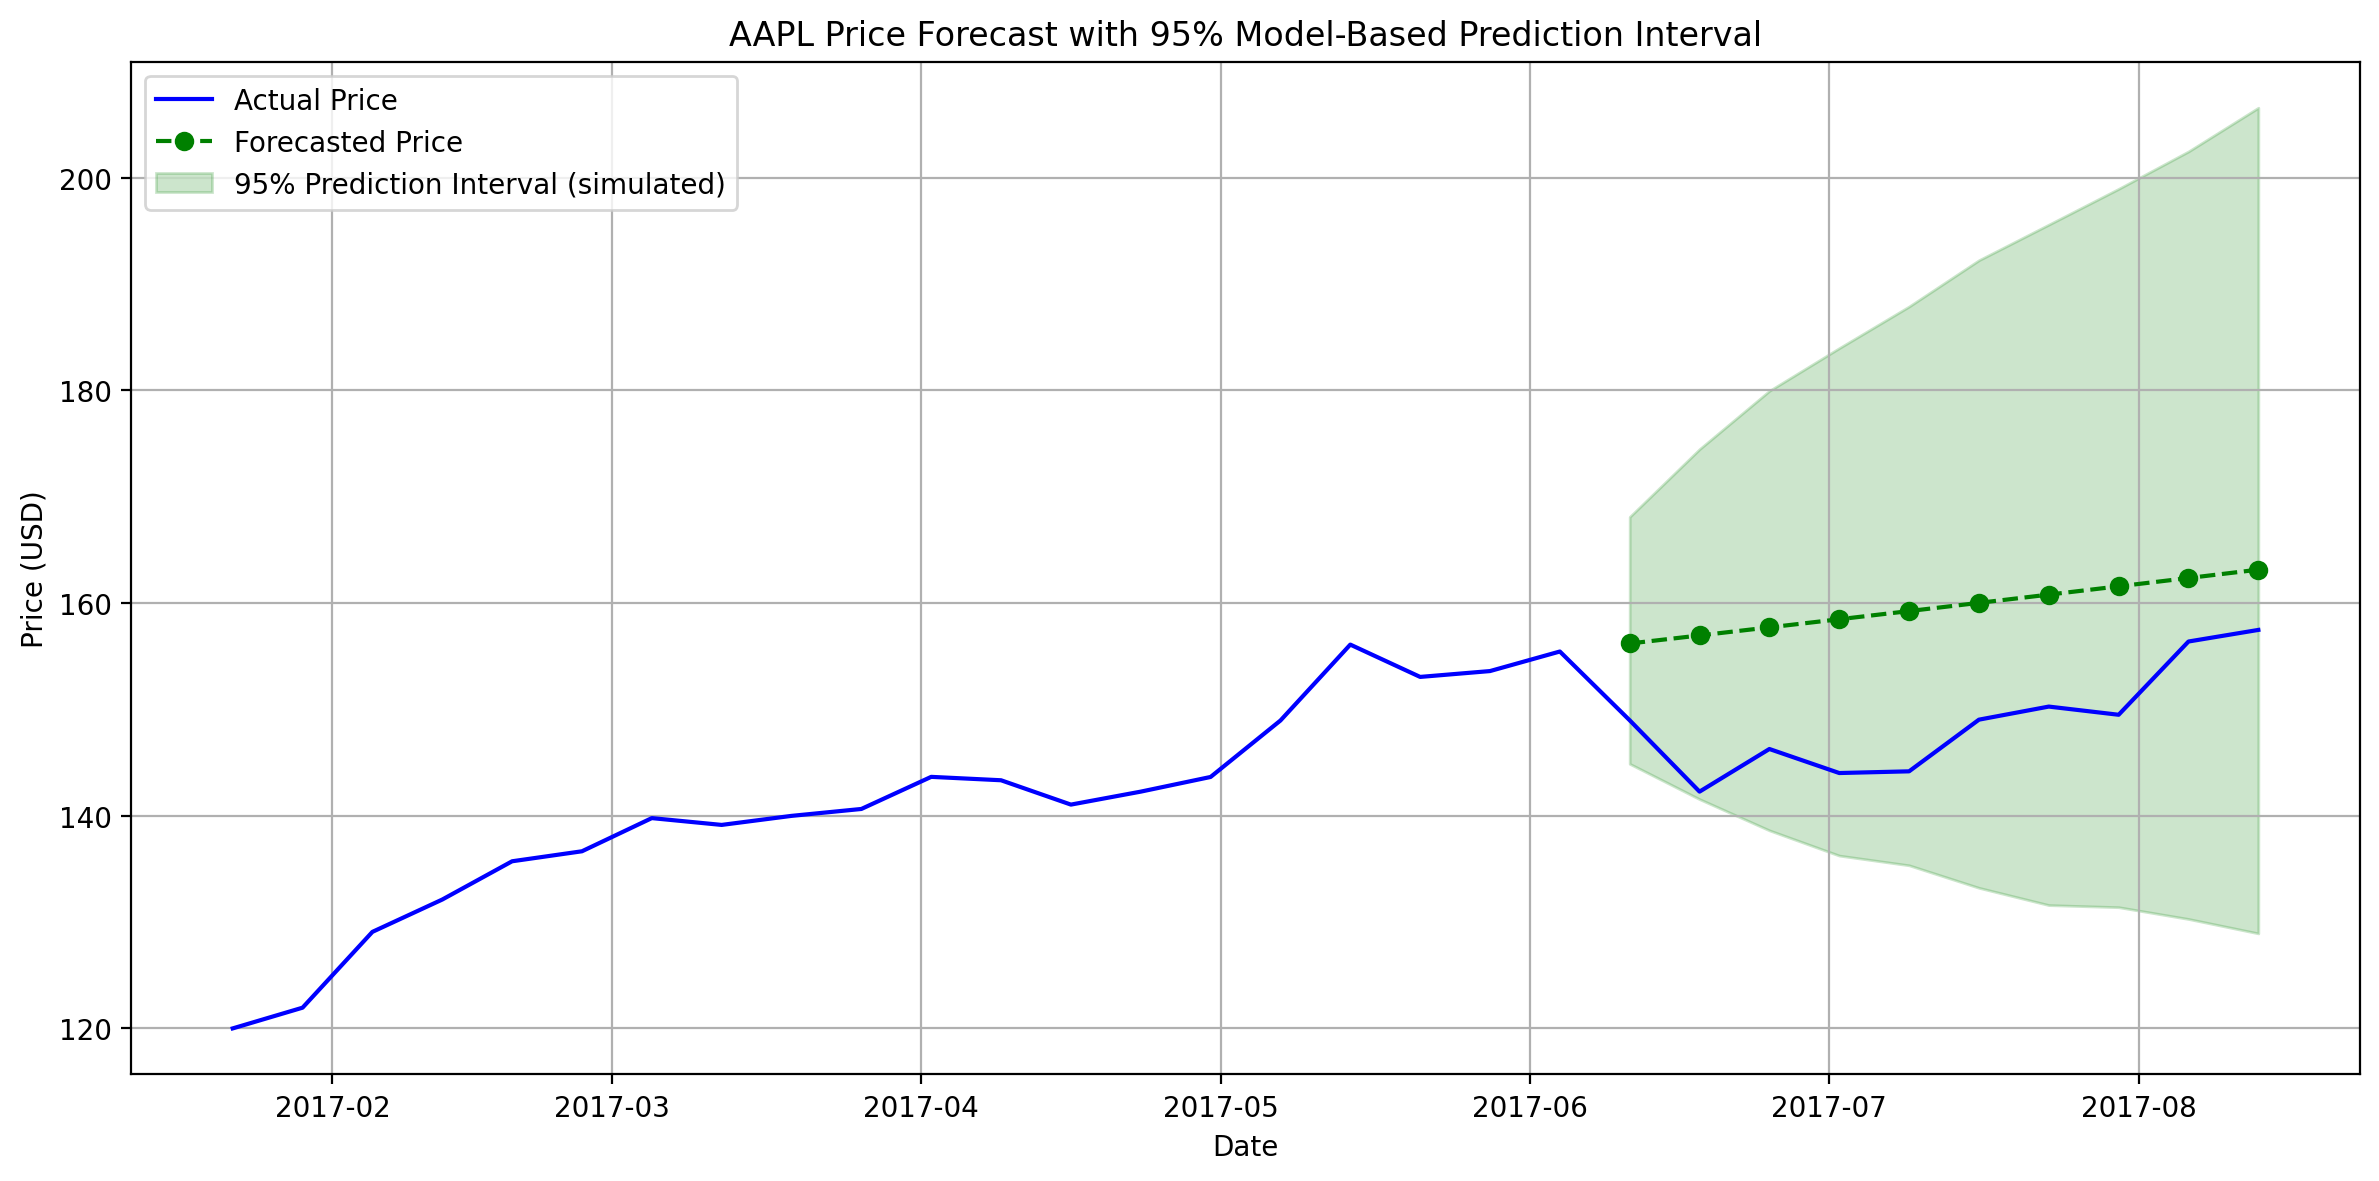

In [14]:
steps = 10  # Number of future weeks to forecast

# Forecasted log returns (point forecast)
forecast = arima_result.get_forecast(steps=steps)
forecasted_log_returns = forecast.predicted_mean.values

# Starting from the last actual price
last_price = df_week['close'].iloc[split - 1]  # last TRAINING price
forecasted_prices = []
current_price = last_price

for i in range(steps):
    # Forecasted price path
    current_price *= np.exp(forecasted_log_returns[i])
    forecasted_prices.append(current_price)

# Simulate future return paths and convert each to a price path
np.random.seed(42)
n_sims = 5000
sims = np.asarray(arima_result.simulate(nsimulations=steps, repetitions=n_sims, anchor='end')).reshape(steps, n_sims)
price_paths = last_price * np.exp(np.cumsum(sims, axis=0))
lower_prices = np.percentile(price_paths, 2.5, axis=1)
upper_prices = np.percentile(price_paths, 97.5, axis=1)

# Generate forecast dates
forecast_dates = df_week.index[split:split + steps]  # first `steps` test weeks

# Plot actual prices, forecast, and prediction interval
plt.figure(figsize=(12, 6))
plt.plot(df_week['close'].iloc[split - 20:split + steps], label='Actual Price', color='blue')
plt.plot(forecast_dates, forecasted_prices, label='Forecasted Price', color='green', linestyle='--', marker='o')
plt.fill_between(forecast_dates, lower_prices, upper_prices, color='green', alpha=0.2, label='95% Prediction Interval (simulated)')
plt.title("AAPL Price Forecast with 95% Model-Based Prediction Interval")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
print("Simulation shape:", np.asarray(sims).shape)
print("Price paths shape:", price_paths.shape)
print("Expected shape:", (steps, n_sims))
print("Lower bounds:", lower_prices)
print("Upper bounds:", upper_prices)

Simulation shape: (10, 5000)
Price paths shape: (10, 5000)
Expected shape: (10, 5000)
Lower bounds: [144.88681094 141.56031647 138.62508302 136.25314658 135.3397141
 133.22306122 131.59831711 131.4001303  130.29163586 128.93751548]
Upper bounds: [168.11246003 174.48666196 179.97138822 183.98947052 187.90374769
 192.25674897 195.60483371 198.96902101 202.48781613 206.5980473 ]


## Step 11: Residual Diagnostics – How Well Did ARIMA Fit?

After fitting the ARIMA model on the training period, it's essential to analyze its **residuals** (errors, computed on the training data) to ensure the model captured all meaningful structure in the data.

We perform 3 diagnostics:

1. **Time Plot of Residuals**  
   Checks if residuals fluctuate randomly around zero (white noise)

2. **Histogram of Residuals**  
   Visualizes if the errors follow a roughly normal distribution

3. **ACF Plot of Residuals**  
   Detects remaining autocorrelation in residuals — if there's any, the model may be missing something

We also run formal tests in the cell after the plots:
- **Ljung-Box** on the residuals (leftover autocorrelation)
- **Ljung-Box and ARCH-LM** on the *squared* residuals (volatility clustering, which an ARIMA model cannot capture)

📌 If residuals:
- Are centered around zero ✅  
- Have no autocorrelation ✅  
- Resemble white noise ✅  
→ Then the model is considered well-fitted.


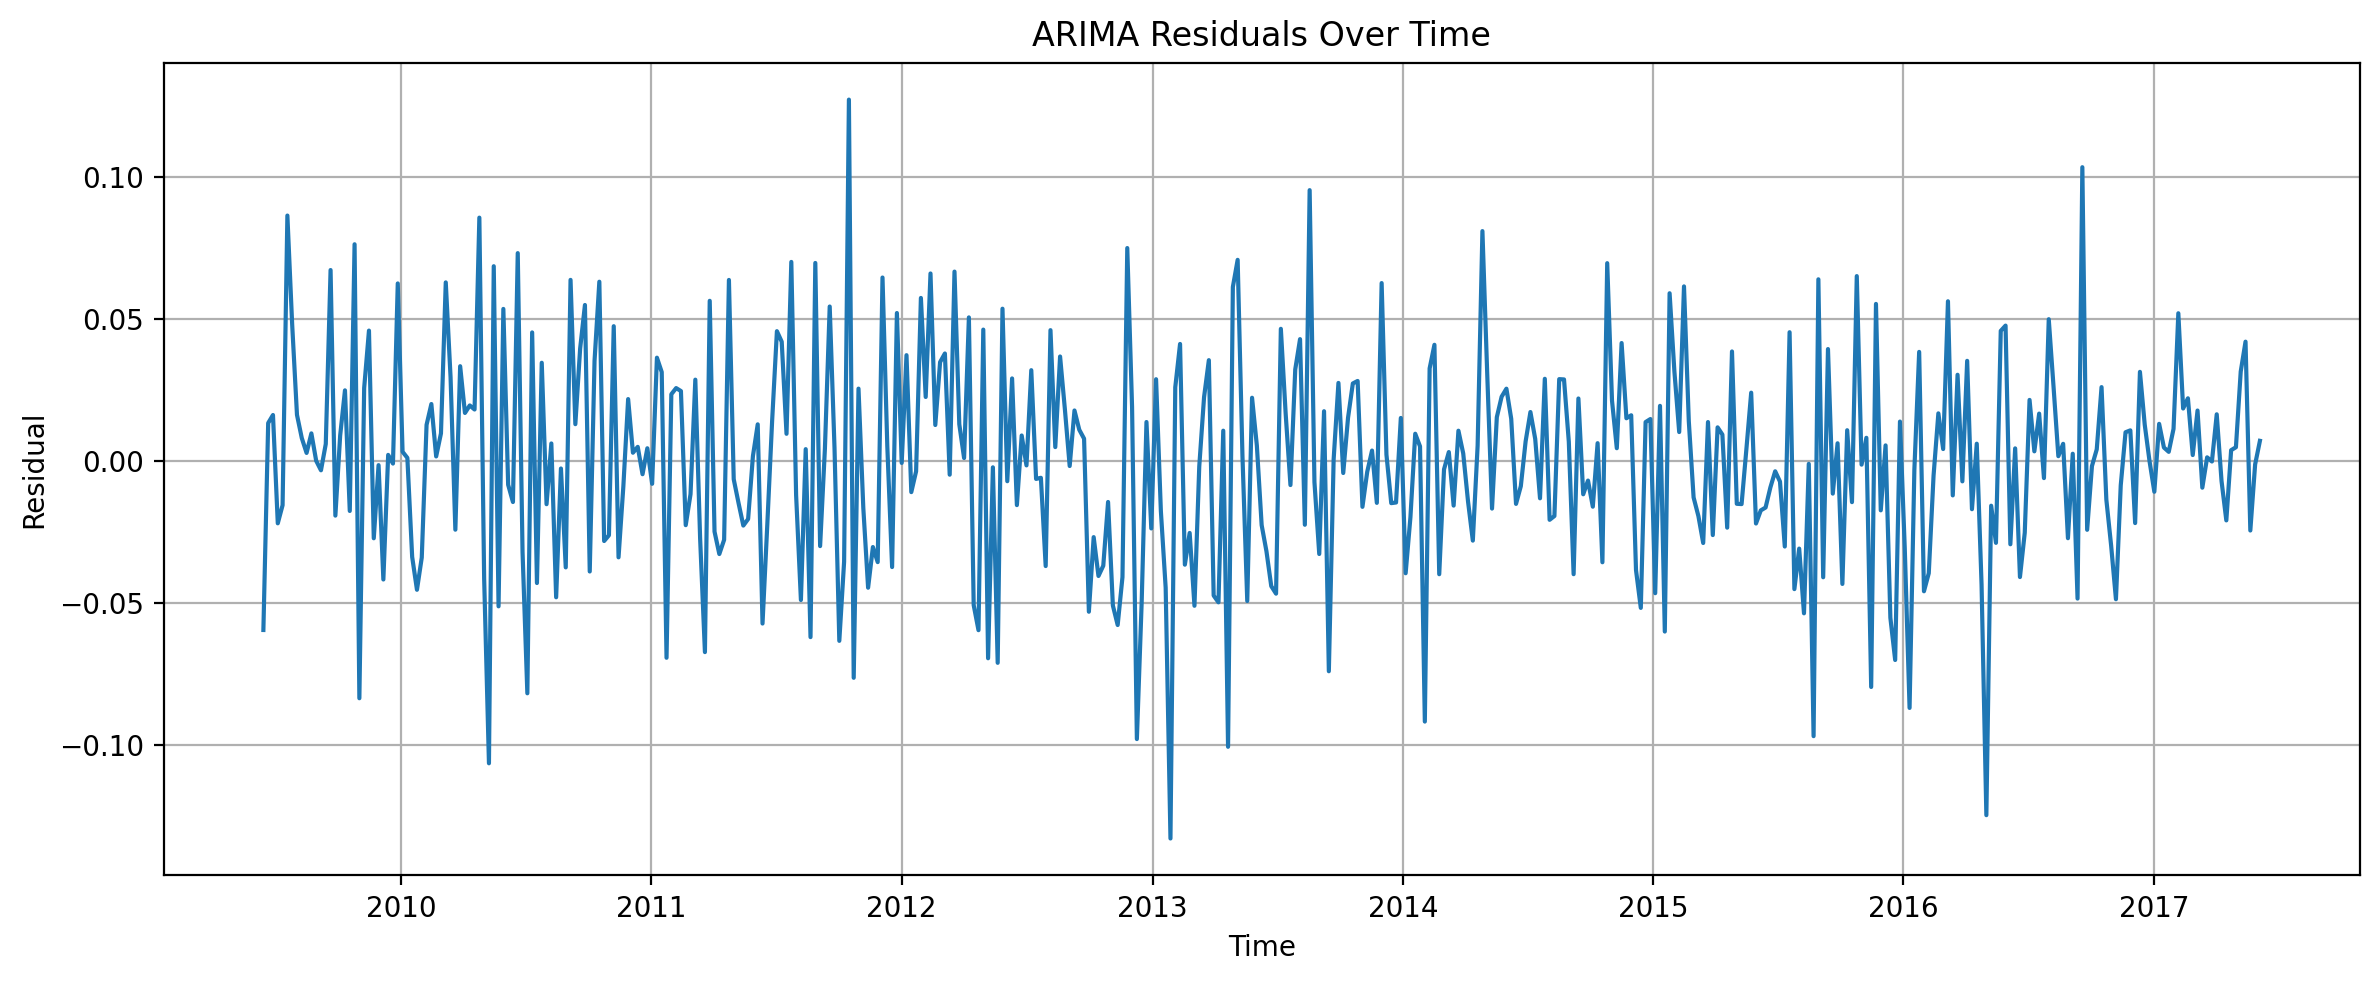

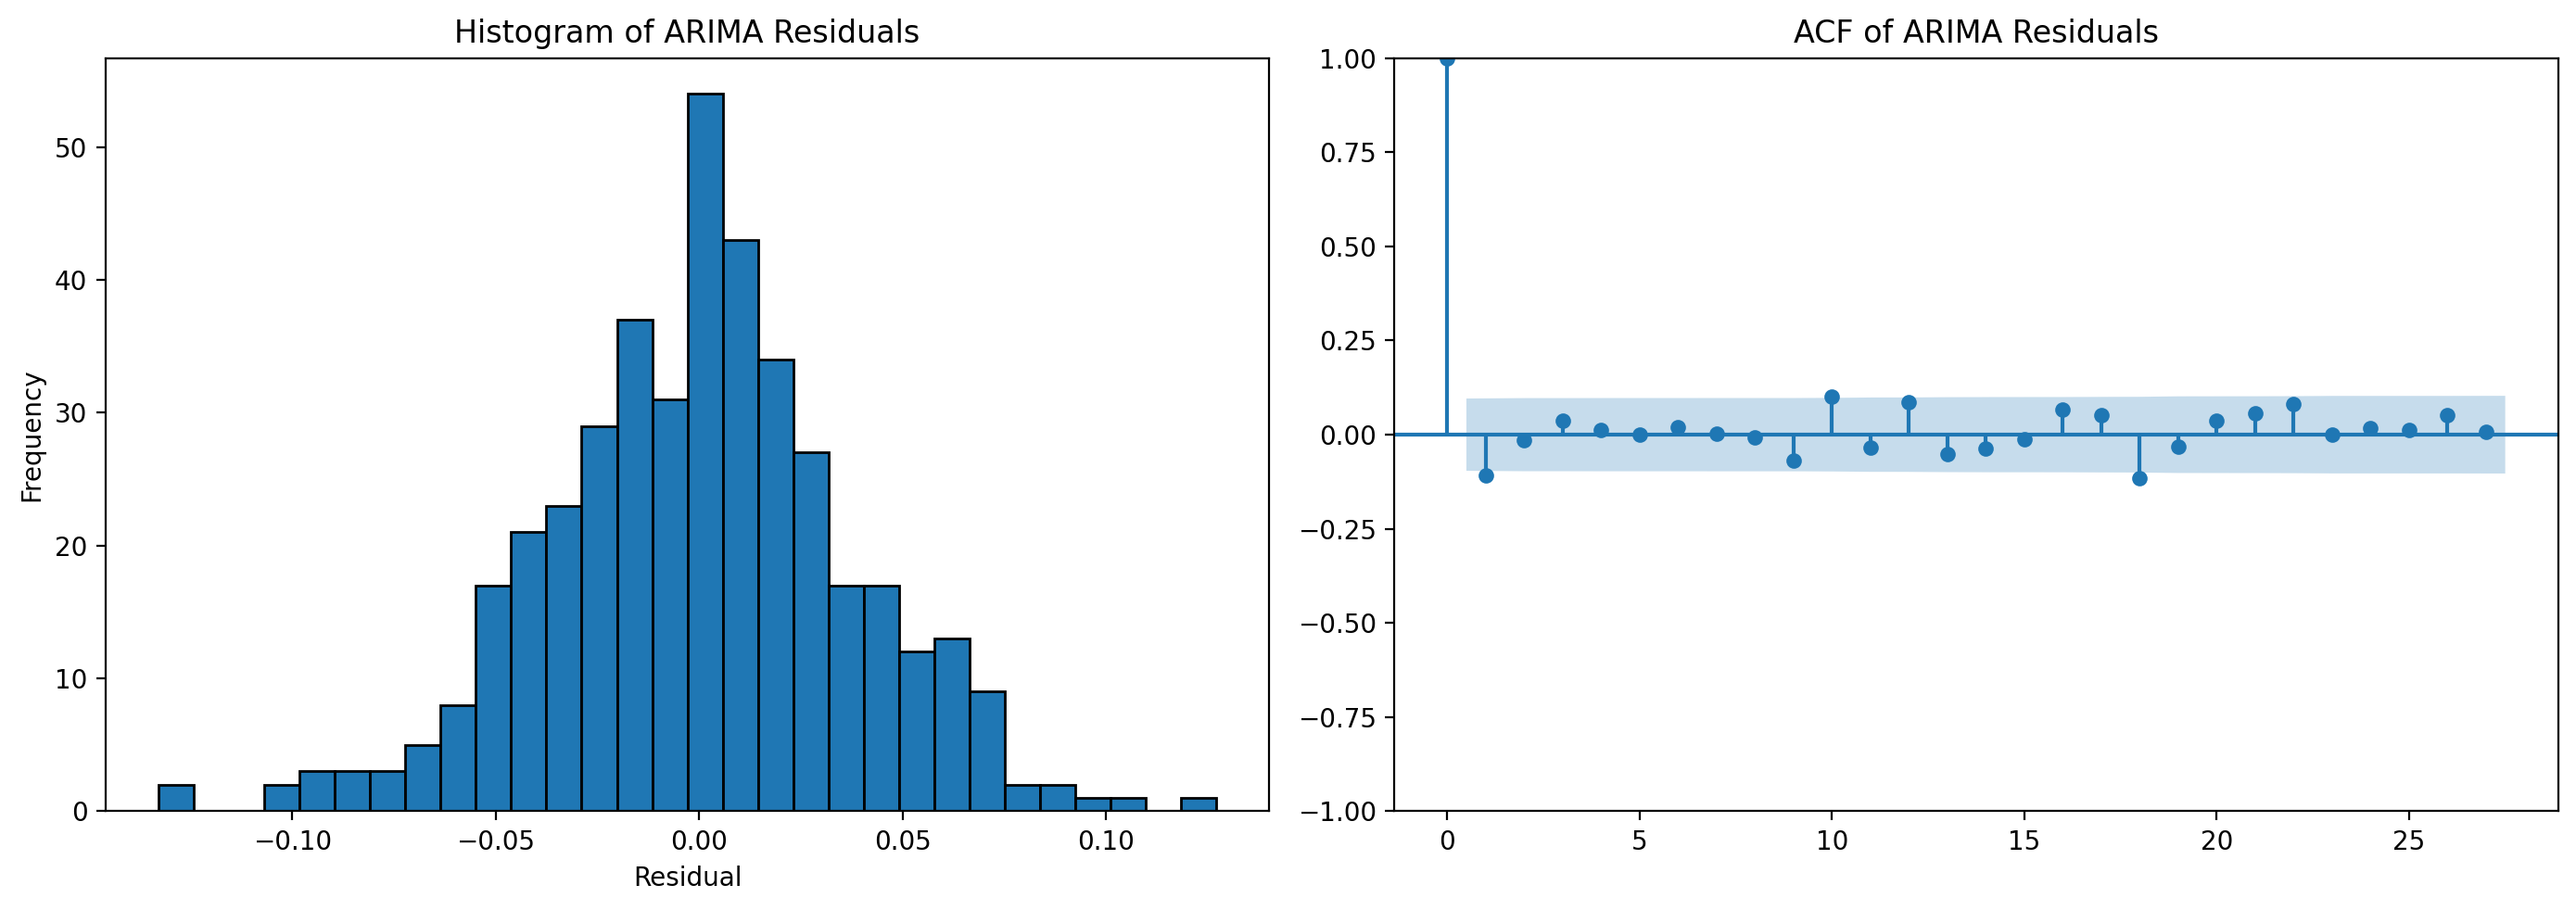

In [16]:
# Extract residuals from the ARIMA model
residuals = arima_result.resid

# Plot residuals over time
plt.figure(figsize=(12, 5))
plt.plot(residuals)
plt.title("ARIMA Residuals Over Time")
plt.xlabel("Time")
plt.ylabel("Residual")
plt.grid(True)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
ax[0].hist(residuals, bins=30, edgecolor='black')
ax[0].set_title("Histogram of ARIMA Residuals")
ax[0].set_xlabel("Residual")
ax[0].set_ylabel("Frequency")

# ACF plot
plot_acf(residuals, ax=ax[1])
ax[1].set_title("ACF of ARIMA Residuals")

plt.tight_layout()
plt.show()



### Residual Diagnostics: Findings and Interpretation

The residual diagnostic plots were examined to assess the adequacy of the selected ARIMA(0,0,0) model fitted to the training returns.

**1. Residuals Over Time**
- The residuals fluctuate around zero, with no clear long-term trend.
- Several large positive and negative residuals indicate weeks with substantial differences between actual and fitted returns.
- The spikes suggest that some market movements are not fully captured by the model.

**2. Distribution of Residuals**
- The histogram shows that most residuals are concentrated around zero.
- The distribution is approximately bell-shaped, although some extreme values and possible tail deviations are visible.
- Normality cannot be confirmed from the histogram alone.

**3. Autocorrelation Function (ACF)**
- Most residual autocorrelation values fall within the 95% confidence bounds.
- A few lags appear to exceed these bounds, suggesting possible remaining autocorrelation.
- A Ljung–Box test is needed to assess whether residual autocorrelation is statistically significant.

**Overall Finding**

The residuals are generally centered around zero, but the diagnostic plots alone do not establish that they behave as independent random noise. Further testing is required to assess residual autocorrelation and the adequacy of the ARIMA model.


In [17]:
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
import scipy.stats as st

resid = residuals.iloc[max(p_order, q_order):]

lb_resid = acorr_ljungbox(resid, lags=[10, 20])
print("Ljung-Box on residuals (H0: no autocorrelation):")
print(lb_resid)

lb_sq = acorr_ljungbox(resid**2, lags=[10, 20])
print("\nLjung-Box on squared residuals (H0: no volatility clustering):")
print(lb_sq)

lm, lm_p, _, _ = het_arch(resid, nlags=10)
print(f"\nARCH-LM test: stat={lm:.2f}, p-value={lm_p:.4f}")
excess_kurt = st.kurtosis(resid)
print(f"Excess kurtosis of residuals: {excess_kurt:.2f} (0 would be normal)")

Ljung-Box on residuals (H0: no autocorrelation):
      lb_stat  lb_pvalue
10  12.211110   0.271176
20  27.923657   0.111219

Ljung-Box on squared residuals (H0: no volatility clustering):
      lb_stat  lb_pvalue
10   8.710549   0.559776
20  24.243572   0.231914

ARCH-LM test: stat=8.70, p-value=0.5609
Excess kurtosis of residuals: 0.56 (0 would be normal)


**Overall Conclusion**

The diagnostic tests show no statistically significant evidence of residual autocorrelation or ARCH effects at the selected lags. These findings support the adequacy of the model in these specific respects, but they do not prove that the residuals are independent, normally distributed, or free of all remaining patterns. The model's forecasting performance must still be assessed using out-of-sample results.

## Results Summary

This cell collects the key numbers from the steps above and states the verdicts that follow from them. Use these numbers in the conclusion.

In [18]:
print("=== RESULTS SUMMARY ===")
print(f"Selected order (BIC, training data only): ARIMA({p_order},0,{q_order})")
print(f"Train / test weeks: {split} / {len(test)}")

print(f"\nFixed-origin backtest   ARIMA: MSE={mse:.6f}, MAE={mae:.4f}   |   train-mean baseline: MSE={mse_base:.6f}, MAE={mae_base:.4f}")
print("\nRolling one-step-ahead backtest:")
print(results.round(5))
print(f"Out-of-sample R^2 vs historical mean: {oos_r2:.4f}   |   Diebold-Mariano p-value: {dm_p:.3f}")
print(f"95% interval coverage on test weeks: {coverage:.1%}")

print(f"\nLjung-Box p-values, training residuals (lag 10 / 20): {lb_resid['lb_pvalue'].iloc[0]:.3f} / {lb_resid['lb_pvalue'].iloc[1]:.3f}")
print(f"Ljung-Box p-values, training squared residuals (lag 10 / 20): {lb_sq['lb_pvalue'].iloc[0]:.3f} / {lb_sq['lb_pvalue'].iloc[1]:.3f}")
print(f"ARCH-LM p-value: {lm_p:.4f}   |   excess kurtosis: {excess_kurt:.2f}")

print("\n--- Verdicts ---")
if abs(oos_r2) < 0.001:
    print("Forecast skill: ARIMA is essentially identical to the historical-mean baseline (out-of-sample R^2 is about 0), so it adds no predictive value.")
elif oos_r2 > 0 and dm_p < 0.05:
    print("Forecast skill: ARIMA beats the historical-mean baseline, and the difference is statistically significant.")
elif oos_r2 > 0:
    print("Forecast skill: ARIMA has slightly lower error than the baseline, but the difference is not statistically significant.")
else:
    print("Forecast skill: ARIMA does NOT beat the historical-mean baseline out-of-sample.")

if (lb_resid['lb_pvalue'] < 0.05).any():
    print("Residuals: significant autocorrelation remains, so the mean model is missing structure.")
else:
    print("Residuals: no significant autocorrelation remains.")

if lm_p < 0.05 or (lb_sq['lb_pvalue'] < 0.05).any():
    print("Variance: volatility clustering is present, so constant-variance intervals are unreliable (too wide in calm periods, too narrow in turbulent ones). A GARCH model is the natural next step.")
else:
    print("Variance: no significant volatility clustering detected.")

if coverage < 0.90:
    print(f"Interval: the 95% interval captured only {coverage:.1%} of test returns, so it is overconfident.")
elif coverage > 0.99:
    print(f"Interval: the 95% interval captured {coverage:.1%} of test returns, so it is wider than necessary.")
else:
    print(f"Interval: coverage of {coverage:.1%} is close to the 95% target.")

=== RESULTS SUMMARY ===
Selected order (BIC, training data only): ARIMA(0,0,0)
Train / test weeks: 417 / 105

Fixed-origin backtest   ARIMA: MSE=0.001411, MAE=0.0277   |   train-mean baseline: MSE=0.001411, MAE=0.0277

Rolling one-step-ahead backtest:
                     MSE      MAE  Directional acc.
ARIMA (rolling)  0.00141  0.02772           0.57143
Historical mean  0.00141  0.02772           0.57143
Zero return      0.00140  0.02789               NaN
Out-of-sample R^2 vs historical mean: 0.0000   |   Diebold-Mariano p-value: 0.336
95% interval coverage on test weeks: 93.3%

Ljung-Box p-values, training residuals (lag 10 / 20): 0.271 / 0.111
Ljung-Box p-values, training squared residuals (lag 10 / 20): 0.560 / 0.232
ARCH-LM p-value: 0.5609   |   excess kurtosis: 0.56

--- Verdicts ---
Forecast skill: ARIMA is essentially identical to the historical-mean baseline (out-of-sample R^2 is about 0), so it adds no predictive value.
Residuals: no significant autocorrelation remains.
Varian

## Final Conclusion

### Data and Methodology

This project analysed weekly Apple Inc. (AAPL) log returns, calculated using the closing price from the last trading day of each week. The dataset was divided chronologically into 417 training observations and 105 test observations. Model selection was performed using the training data only. Both fixed-origin and rolling one-step-ahead backtesting were used to evaluate out-of-sample forecasting performance.

### Stationarity

The Augmented Dickey–Fuller (ADF) test on weekly log returns produced a test statistic of -24.72 with a p-value close to zero. This provides strong evidence against the null hypothesis of a unit root, supporting the treatment of weekly log returns as stationary for this analysis.

### Model Selection

BIC selected **ARIMA(0,0,0)**, a model with a constant mean and random errors but no autoregressive or moving-average terms. The estimated mean weekly log return was 0.0048 (`p = 0.009`), equivalent to approximately 0.48% per week in log-return terms. The estimated error variance was 0.0014.

AIC slightly favoured models with one AR or MA term, suggesting that a more complex model might capture some short-term dependence. However, BIC favoured the simpler specification. This highlights the trade-off between model complexity and goodness of fit.

### Out-of-Sample Forecasting Performance

ARIMA(0,0,0) did not demonstrate predictive improvement over the naive benchmarks.

- **Fixed-origin backtest:** ARIMA and the training-mean baseline both achieved an MSE of 0.001411 and an MAE of 0.0277.
- **Rolling one-step-ahead backtest:** ARIMA and the historical-mean baseline achieved an MSE of 0.00141 and an MAE of 0.02772. The zero-return baseline achieved a marginally lower MSE of 0.00140.
- **Out-of-sample R²:** 0.0000 relative to the historical-mean baseline.
- **Diebold–Mariano test:** `p = 0.336`, providing no statistically significant evidence of a difference in forecast accuracy.
- **Directional accuracy:** 57.1%. This result does not establish predictive skill because the model always forecasts a positive return and 57.1% of the test-period returns were positive.

Overall, the model did not show evidence of useful predictive information beyond a simple historical-mean forecast. This finding applies to the selected model, dataset and evaluation period; it does not prove that stock returns are universally unpredictable.

### Ten-Week Price Forecast

Using data available at the end of the training period (4 June 2017), the ARIMA(0,0,0) model generated a steadily increasing ten-week price forecast. The forecast rose from 156.20 in the first test week to 163.15 in the tenth test week, reflecting the estimated mean weekly log return rather than an ability to predict individual price movements.

Actual prices remained below the point forecast throughout the ten-week period. The actual closing price in the tenth week was 157.48, approximately 3.5% below the forecast of 163.15.

All ten actual prices fell within their corresponding simulated 95% prediction intervals. However, the intervals widened substantially with the forecast horizon, reaching 128.94–206.60 in the tenth week. This illustrates the accumulation of forecast uncertainty over time. These intervals are model-based estimates, not guarantees about future prices.

### Residual Diagnostics

The Ljung–Box tests on training residuals produced p-values of 0.271 at lag 10 and 0.111 at lag 20. Therefore, the tests did not find statistically significant residual autocorrelation at those selected lags.

The corresponding tests on squared residuals produced p-values of 0.560 and 0.232, while the ARCH-LM test produced a p-value of 0.561. These results provide no statistically significant evidence of residual volatility clustering at the tested lags.

Excess kurtosis was 0.56, suggesting somewhat heavier tails than a normal distribution. The Jarque–Bera test was borderline significant (`p = 0.04`), so normality should not be assumed without qualification.

Failure to reject these diagnostic null hypotheses does not prove that the residuals are independent, normally distributed or homoscedastic.

### Limitations

- The analysis focused on one stock and one historical period.
- The model used only past returns and did not incorporate external explanatory variables.
- Transaction costs and investment implementation were not considered.
- Weekly aggregation may conceal patterns present in daily returns.
- The test sample contained 105 observations, limiting the precision of comparisons between models.
- Historical forecast performance does not guarantee future performance.

### Future Work

Potential extensions include:

1. Comparing ARIMA(1,0,0) and ARIMA(0,0,1) through the same out-of-sample evaluation procedure.
2. Investigating volatility dynamics using GARCH models on daily returns.
3. Exploring seasonal models only if a plausible seasonal structure is identified.
4. Evaluating models such as XGBoost or LSTM using carefully designed chronological validation and appropriate naive benchmarks.
5. Investigating whether additional features, such as trading volume or macroeconomic indicators, improve forecasts beyond the historical-mean baseline.

### Overall Finding

The project demonstrates a complete time-series workflow involving data preparation, stationarity testing, information-criterion-based model selection, chronological backtesting, forecast evaluation and residual diagnostics. Although ARIMA(0,0,0) provided a useful baseline, it did not outperform simple benchmarks. The central finding is that model selection and a visually plausible forecast are not sufficient evidence of predictive value; performance must be demonstrated through out-of-sample evaluation.